In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# read the dataset
df = pd.read_csv("data/california_housing.csv")

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (16512, 8) | Test shape: (4128, 8)


In [2]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ),
}

results = []
trained_pipelines = {}

for name, model in models.items():
    # create a pipeline with RobustScaler and the model
    pipe = Pipeline([
        ("scaler", RobustScaler()),
        ("model", model)
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({"Model": name, "MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2 Score": round(r2, 4)})
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by="RMSE")
results_df

,Model,MAE,RMSE,R2 Score
3,Random Forest,0.3325,0.5122,0.7998
0,Linear Regression,0.5332,0.7456,0.5758
1,Ridge Regression,0.5332,0.7456,0.5758
2,Lasso Regression,0.5364,0.7470,0.5741


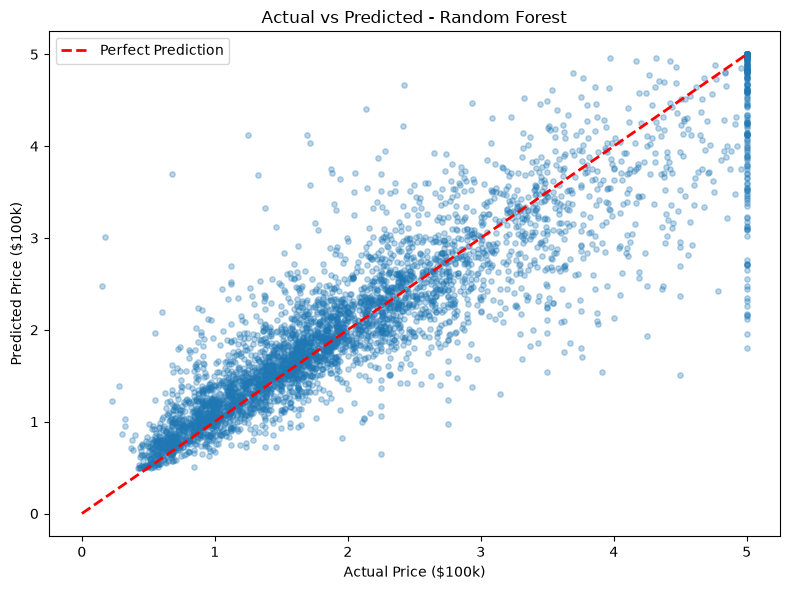

Saved best model: Random Forest -> models/best_model.joblib


In [3]:
# best model selection based on RMSE
best_model_name = results_df.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]
y_pred_best = best_pipe.predict(X_test)

# plot actual vs predicted values for the best model
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, s=15)
plt.plot([0, 5], [0, 5], "r--", lw=2, label="Perfect Prediction")
plt.xlabel("Actual Price ($100k)")
plt.ylabel("Predicted Price ($100k)")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150)
plt.show()

# compress and save the best model
os.makedirs("models", exist_ok=True)
joblib.dump(best_pipe, "models/best_model.joblib", compress=3)
print(f"Saved best model: {best_model_name} -> models/best_model.joblib")

> **Model Selection Insight:**  **Random Forest** significantly outperforms linear models (`Linear`, `Ridge`, and `Lasso`), achieving the lowest error (**RMSE: 0.5122**, **MAE: 0.3325**) and explaining nearly **80% of the variance ($R^2 = 0.7998$)** compared to ~57.6% for linear models. This happens because housing prices depend heavily on non-linear geographic patterns (`Latitude` & `Longitude`) that tree-based ensembles capture much better than straight-line models.